In [46]:
import os
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from google import genai
load_dotenv()
key1=os.environ['OPENROUTER_API_KEY']
key2=os.environ['GEMINI_API_KEY']

In [47]:
llm1 = ChatOpenAI(
    model="openrouter/free",
    base_url="https://openrouter.ai/api/v1",
    api_key=key1
)

In [48]:
llm2 = genai.Client(
    api_key=key2
)

In [49]:
response1 = llm1.invoke("What is Python?")

print(response1.content)

**Python** is a high-level, interpreted programming language known for its simplicity, readability, and versatility. It was created by **Guido van Rossum** and first released in 1991.

Here is a breakdown of what makes Python unique and why it is so widely used today:

### 1. Key Characteristics
*   **Easy to Learn:** Python’s syntax is designed to look like natural English. It uses significant whitespace (indentation) to define code blocks, which helps prevent bugs and makes code easy to read.
*   **Interpreted Language:** Unlike languages such as C or Java that are compiled into machine code before running, Python code is executed directly by an interpreter. This allows developers to test small pieces of code immediately without needing a complex build process.
*   **"Batteries Included":** Python comes with a massive standard library. This means you don’t need to search for external tools to perform basic tasks; Python has built-in modules for file handling, web requests, system adm

In [50]:
response2 = llm2.models.generate_content(
    model="gemini-3.6-flash",
    contents="What is Python?"
)

print(response2.text)

**Python** is a high-level, interpreted, general-purpose programming language known for its simplicity and readability. Created by Guido van Rossum and first released in 1991, Python is designed to emphasize code readability, using clean syntax that closely resembles natural English.

Because it is so versatile, Python is currently one of the most popular programming languages in the world, used by beginners and tech giants (like Google, Netflix, NASA, and Meta) alike.

---

### Key Features of Python

1. **Easy to Read and Learn:** Python code uses English keywords and straightforward formatting (like indentation) instead of complex punctuation, making it easy for beginners to understand.
2. **Interpreted Language:** Python code is executed line-by-line, which makes testing and debugging faster (you don't need to compile the code before running it).
3. **Dynamically Typed:** You don’t need to explicitly declare variable types (like numbers, text, etc.); Python figures it out automatic

In [51]:
print(llm1)


metadata={'lc_versions': {'langchain-core': '1.6.3', 'langchain': '1.4.0', 'langchain-openai': '1.6.2'}} client=<openai.resources.chat.completions.completions.Completions object at 0x781f9464dbe0> async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x781f9464ddc0> root_client=<openai.OpenAI object at 0x781f94656180> root_async_client=<openai.AsyncOpenAI object at 0x781f945b54f0> model_name='openrouter/free' model_kwargs={} openai_api_key=SecretStr('**********') openai_api_base='https://openrouter.ai/api/v1' stream_chunk_timeout=120.0


In [52]:
res = llm1.invoke("Hello what is your name")

In [53]:
print(res.content)

User Safety: safe


In [54]:
#basic agent 1
from langchain.agents import create_agent

agent = create_agent(
    model=llm,
    tools=[],
    system_prompt="you are an helpul assistant"
)

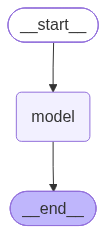

In [55]:
agent

In [56]:
res = agent.invoke({
    "messages":[{"role":"user","content":"what is the current time in London"}]
    })

In [57]:
print(res['messages'][1].content)



I don't have real-time information, so I can't tell you the exact current time in London. For the most accurate time, I'd recommend checking a world clock, your phone, or a website like time.is. London is on GMT (UTC+0) in winter and BST (UTC+1) in summer, so that might help you figure it out if you know your local time.


In [58]:
help(print)

Help on built-in function print in module builtins:

print(*args, sep=' ', end='\n', file=None, flush=False)
    Prints the values to a stream, or to sys.stdout by default.

    sep
      string inserted between values, default a space.
    end
      string appended after the last value, default a newline.
    file
      a file-like object (stream); defaults to the current sys.stdout.
    flush
      whether to forcibly flush the stream.



In [59]:
from datetime import datetime
from zoneinfo import ZoneInfo
from langchain_core.tools import tool

@tool
def get_city_time(city: str) -> str:
    """Get the current time of a city."""

    timezones = {
        "india": "Asia/Kolkata",
        "london": "Europe/London",
        "new york": "America/New_York",
        "tokyo": "Asia/Tokyo",
        "dubai": "Asia/Dubai",
    }

    timezone = timezones.get(city.lower())

    if timezone is None:
        return "City not found"

    current_time = datetime.now(ZoneInfo(timezone))

    return current_time.strftime("%Y-%m-%d %I:%M:%S %p")

In [60]:
agent = create_agent(
    model=llm,
    tools=[get_city_time,],
    system_prompt="you are an helpul assistant"
)

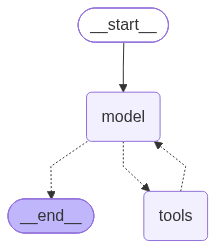

In [61]:
agent

In [62]:
res = agent.invoke({
    "messages":[{"role":"user","content":"who is the pm of india"}]
    })

In [63]:
res

{'messages': [HumanMessage(content='who is the pm of india', additional_kwargs={}, response_metadata={}, id='491f8372-d14f-44ec-81f4-7358fc271480'),
  AIMessage(content='The Prime Minister of India is **Narendra Modi**.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 47, 'prompt_tokens': 286, 'total_tokens': 333, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 37, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'nex-agi/nex-n2.5-mini:free', 'system_fingerprint': None, 'id': 'gen-1789466303-V971JbwOVGyY3NPQCIMw

In [70]:
res = agent.invoke({
    "messages":[{"role":"user","content":"what is the current time in London"}]
    })

In [69]:
res

{'messages': [HumanMessage(content='what is the current time in London', additional_kwargs={}, response_metadata={}, id='ff6b62c7-1771-423c-a3ab-5b53e20338c9'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 254, 'total_tokens': 315, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 46, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'inclusionai/ling-3.0-flash-sante:free', 'system_fingerprint': None, 'id': 'gen-1789466304-d1APeQosi4IaOTBFc3Qe', 'finish_reason': 'tool_

In [72]:
print(res["messages"][-1].content)

The current time in London is **10:59 AM** on September 15, 2026.


In [67]:
print(res)

{'messages': [HumanMessage(content='what is the current time in London', additional_kwargs={}, response_metadata={}, id='ff6b62c7-1771-423c-a3ab-5b53e20338c9'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 254, 'total_tokens': 315, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 46, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'inclusionai/ling-3.0-flash-sante:free', 'system_fingerprint': None, 'id': 'gen-1789466304-d1APeQosi4IaOTBFc3Qe', 'finish_reason': 'tool_ca

In [99]:
help(max)

Help on built-in function max in module builtins:

max(...)
    max(iterable, *[, default=obj, key=func]) -> value
    max(arg1, arg2, *args, *[, key=func]) -> value

    With a single iterable argument, return its biggest item. The
    default keyword-only argument specifies an object to return if
    the provided iterable is empty.
    With two or more arguments, return the largest argument.



In [100]:
max(5,2)

5

In [81]:
from langchain.chat_models import init_chat_model
model=init_chat_model("google_genai:gemini-3.6-flash")
response=model.invoke("why cars have breaks?")
response.content

[{'type': 'text',
  'text': "Cars have **brakes** for several crucial reasons, all centered around **safety, control, and physics**. \n\nHere are the main reasons why cars need brakes:\n\n### 1. To Slow Down and Stop\nThe most basic reason for brakes is to allow the driver to reduce speed or bring the car to a complete stop whenever necessary—such as at red lights, stop signs, in heavy traffic, or at your destination.\n\n### 2. Safety and Collision Avoidance\nBrakes are the primary safety feature of any vehicle. They allow drivers to react to unexpected hazards, such as a child running into the street, another car stopping suddenly, or an obstacle on the road. Without brakes, avoiding accidents would be nearly impossible.\n\n### 3. Speed Control (Driver Control)\nBrakes give the driver control over the vehicle's momentum. For example:\n* **Going downhill:** Gravity naturally speeds a car up when going down a hill; brakes prevent the car from moving too fast.\n* **Taking turns:** Driver

Streaming and Batch

//
Streaming: Streaming means data is processed as soon as it arrives, without waiting for all the data. For example, a live video or ChatGPT generating its response word by word.

Batch: Batch means data is collected first and then processed all at once. For example, generating monthly salary reports or processing all sales data at the end of the day.



In [82]:
model.stream("what is streaming and batching in llm explain in 200 words")

<generator object BaseChatModel.stream at 0x781f9435c800>

In [84]:
for chunks in model.stream("what is streaming and batching in llm explain in 200 words"):
    print(chunks.text)    

In Large Language Models (LLMs), **streaming** and **batching** represent two
 different strategies for handling model inference, balancing user experience against compute efficiency.

**Streaming** focuses on **real-time delivery and
 low latency**. Instead of waiting for the model to generate a complete response, the system sends output to the user token-
by-token (word-by-word) as it is generated. This dramatically reduces the *Time to First Token
 (TTFT)*, creating an interactive, instant feel. It is the standard approach for user-facing applications like AI
 chatbots.

**Batching** focuses on **throughput and resource efficiency**. Instead of processing single requests individually, the server groups
 multiple user prompts together into a single batch to process them simultaneously on the GPU. This maximizes hardware utilization and lowers operational costs per
 request, though individual response times may be slightly longer. 

**Summary:**
* **Streaming** optimizes for *speed an

In [85]:
responses=model.batch([
    "why is the sky is red in morning in 1 line",
    "why fan using ac current in one line",
    "why rain fall in sea in one line"
])
for response in responses:
    print(response)

content=[{'type': 'text', 'text': 'At sunrise, sunlight travels through a thicker layer of atmosphere, scattering away short blue light and leaving mostly longer red wavelengths visible.', 'extras': {'signature': 'EsYKCsMKARFNMg94o2FOKNOZiPsMXZq6l+mfruZ+Pk2apnzIold75ittaCxPDmPpH7JjRfuO1acYD7ZDNatrajR+XyI5bzEGm5CZ00sx1QNchVw2zt51RIfuHj/SRqcfMJo0PwWDStPMwbYG9daeZ/BLJ4Q6qjq6c4kCb5SZ6Enxsn4tadJDSMRliE2TAs+cS6pwz469u99+3xfdnjJkAcOPkJf1ATtzUYQKYQACjDhrODWQH+XcBF16WfiK5bT2w6Q2RRIZ70eG4c+7HC0DXS0YiAl/cDooEuRy1eazSCBAVf1aHWBDgLrcViYnB1E8X69QvHXvf2cByrZNjo6oiyg3/oKL2gpXdoAmC/KYcjcSj2CdVRE7EcObQcJjlsxKqw2Wj5cmWVtQU3Tf+G4tDOCyQ8M99YSsPSrTTDW0iFfTH/xsKLHgjDlpDhUEl5CzeCPjPorMR3paA1ekdh/b1D1k7Wr92q6xz/QhzfWcx13jSBIthKRkEBo7UFoSnoGDZxh2YnGUuH7nFPWPlJBLyBYfteVIGkIqtpvsfe9uXtl2yuHqtKFfIZppXdRjp4aKrAAp1VNG+ZtSidKzC7ZZ41UgRfNU+/t8IjoWQG4m3AUNEqq7EybjVLHQUhgYBr23NZTnoIxS01pArD/x/Sox8+8rasC5FohEJrgjTUzg1kp1EYscFAWt64Nup5kcbOdn6UhKbKw5xcN/OVlXEaHNj28LLj9Wt/IGcA1zQRXFCReci+6UHs1cu+DSGn/250sk9WIQjOvCtSVUvyg9rT